# 04 - Search engine evaluation

This notebook is presentation-only. Index construction, TF-IDF/BM25 scoring, repeated queries, parameter sensitivity, and artifact export are performed by `scripts/run_search_experiment.py --config configs/sample.toml`. The report experiment uses the validated 50,000-review sample.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

def find_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file():
            return candidate
    raise RuntimeError('Run the notebook inside the project repository')

ROOT = find_root()
RESULT_DIR = ROOT / 'artifacts' / 'search_engine' / 'sample'

manifest = json.loads((RESULT_DIR / 'run_manifest.json').read_text(encoding='utf-8'))
comparison = pd.read_csv(RESULT_DIR / 'comparison.csv')
rankings = pd.read_csv(RESULT_DIR / 'rankings.csv')
parameters = pd.read_csv(RESULT_DIR / 'bm25_parameters.csv')
assert manifest['status'] == 'COMPLETED'
assert manifest['ranked_queries'] >= 5
assert set(rankings['ranker']) == {'tfidf', 'bm25'}
print(f"Displaying: {RESULT_DIR.relative_to(ROOT)}")
print(f"Documents: {manifest['index_stats']['document_count']:,}")


Displaying: artifacts\search_engine\sample
Documents: 50,000


## Index and experiment summary

In [2]:
stats = manifest['index_stats']
pd.DataFrame({
    'metric': ['documents', 'vocabulary', 'indexed terms', 'average document length',
               'build seconds', 'experiment seconds'],
    'value': [stats['document_count'], stats['vocabulary_size'], stats['total_terms'],
              stats['avgdl'], manifest['build_seconds'], manifest['experiment_seconds']],
})


,metric,value
0,documents,5.000000e+04
1,vocabulary,5.604000e+04
2,indexed terms,5.247734e+06
3,average document length,1.049547e+02
4,build seconds,6.303800e+01
5,experiment seconds,1.319592e+01


In [3]:
comparison_display = comparison[[
    'query', 'overlap_count', 'jaccard', 'top1_match',
    'tfidf_all_query_terms_coverage', 'bm25_all_query_terms_coverage',
    'tfidf_median_ms', 'bm25_median_ms',
]].copy()
comparison_display.style.format({
    'jaccard': '{:.3f}',
    'tfidf_all_query_terms_coverage': '{:.2f}',
    'bm25_all_query_terms_coverage': '{:.2f}',
    'tfidf_median_ms': '{:.1f}',
    'bm25_median_ms': '{:.1f}',
})


,query,overlap_count,jaccard,top1_match,tfidf_all_query_terms_coverage,bm25_all_query_terms_coverage,tfidf_median_ms,bm25_median_ms
0,good service,3,0.176,False,0.90,1.00,287.8,294.9
1,cheap Italian restaurant,3,0.176,False,0.10,0.40,96.6,99.9
2,family friendly atmosphere,6,0.429,False,0.60,1.00,156.8,156.4
3,slow delivery,4,0.250,False,0.10,0.60,30.4,30.9
4,best coffee and breakfast,2,0.111,False,0.10,0.80,404.9,424.7
5,not worth the price,4,0.250,False,0.40,1.00,507.4,521.7


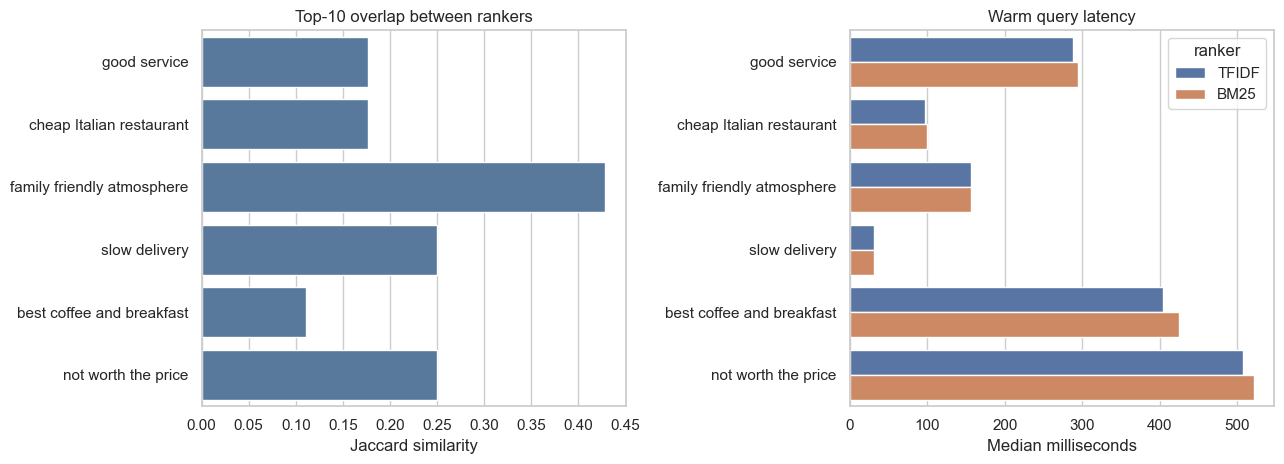

In [4]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=comparison, y='query', x='jaccard', color='#4C78A8', ax=axes[0])
axes[0].set_title('Top-10 overlap between rankers')
axes[0].set_xlabel('Jaccard similarity')
axes[0].set_ylabel('')
latency = comparison.melt(
    id_vars='query', value_vars=['tfidf_median_ms', 'bm25_median_ms'],
    var_name='ranker', value_name='median_ms')
latency['ranker'] = latency['ranker'].str.replace('_median_ms', '', regex=False).str.upper()
sns.barplot(data=latency, y='query', x='median_ms', hue='ranker', ax=axes[1])
axes[1].set_title('Warm query latency')
axes[1].set_xlabel('Median milliseconds')
axes[1].set_ylabel('')
fig.tight_layout()
plt.show()


## Side-by-side rankings

The table below exposes representative retrieved documents rather than treating overlap as relevance. Change `SELECTED_QUERY` to inspect any configured query.

In [5]:
SELECTED_QUERY = comparison.iloc[0]['query']
top = rankings[(rankings['query'] == SELECTED_QUERY) & (rankings['rank'] <= 5)].copy()
top[['ranker', 'rank', 'score', 'business_name', 'stars',
     'document_length', 'matched_query_terms', 'text_excerpt']]


,ranker,rank,score,business_name,stars,document_length,matched_query_terms,text_excerpt
0,tfidf,1,0.391712,First Watch,4.0,8,"[""good"", ""service""]",Fresh and tasty breakfast food and good service.
1,tfidf,2,0.355644,Chabaa Thai Bistro,4.0,14,"[""good"", ""service""]","Good solid food, price OK, service good as wel..."
2,tfidf,3,0.349974,Bailey's,4.0,10,"[""good"", ""service""]","Great food, good selection of beers, and very ..."
3,tfidf,4,0.348863,The Swamp Room,4.0,6,"[""good""]",Good food... Good folks... Good Fun!!!!
4,tfidf,5,0.346186,Steelbach at Armature Works,4.0,19,"[""good"", ""service""]","Good food, and the service was good. Unique me..."
10,bm25,1,4.679561,Idaho Capital Asian Market,5.0,30,"[""good"", ""service""]",Very good stores all vegetables fresh. good se...
11,bm25,2,4.537287,Remoulade,4.0,27,"[""good"", ""service""]",Great place we spontaneously picked. Quick ser...
12,bm25,3,4.534760,Allin's Diner,4.0,13,"[""good"", ""service""]","Good food, good service, good prices. St. Char..."
13,bm25,4,4.468598,Gus's World Famous Fried Chicken,5.0,16,"[""good"", ""service""]",Good food. Chicken was tender and juicy. Good ...
14,bm25,5,4.468177,Commander's Palace,3.0,46,"[""good"", ""service""]","This is a famous institution. The food is ""goo..."


## BM25 parameter sensitivity

Jaccard similarity is measured against the default `k1=1.5, b=0.75` ranking. It describes ranking stability, not relevance quality.

In [6]:
parameter_summary = (parameters.groupby(['k1', 'b'], as_index=False)
                     .agg(mean_jaccard=('default_jaccard', 'mean'),
                          top1_match_rate=('top1_matches_default', 'mean'),
                          mean_document_length=('mean_document_length', 'mean')))
parameter_summary.style.format({
    'mean_jaccard': '{:.3f}', 'top1_match_rate': '{:.2f}',
    'mean_document_length': '{:.1f}',
})


,k1,b,mean_jaccard,top1_match_rate,mean_document_length
0,0.500000,0.750000,0.782,1.00,54.4
1,1.500000,0.000000,0.095,0.00,328.5
2,1.500000,0.750000,1.000,1.00,48.8
3,1.500000,1.000000,0.480,0.67,27.8
4,2.000000,0.750000,0.791,1.00,40.2


## Interpretation constraints

TF-IDF cosine normalizes complete document and query vectors, whereas BM25 saturates repeated term frequency and explicitly normalizes document length. Different Top-10 lists therefore demonstrate different ranking behaviour, not that either model is more relevant. No human relevance judgements were collected, so overlap, term coverage, latency, and parameter sensitivity must not be reported as precision, recall, or model accuracy.